
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

**Exercise 2**: Read about the Ising model 1D, 2D and 3D and write a short recopilation. 

**Exercise 3**:

## Modelo de Ising 3D

Como aplicación de la distribución canónica en `Física estadística` tenemos el modelo de **Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material. Consultar: (https://en.wikipedia.org/wiki/Ising_model)

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 3D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación mediante el uso del método de **Metrópolis Monte Carlo** para este sistema. Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,G < H < +30\,G$ (Gauss).  

In [15]:
#Librerias
import numpy as np
import random
import math
import matplotlib.pyplot as plt
from scipy import integrate

# Solución

## Ejercicio 1

Usamos la rutina general de clase `monte_carlo_integration`, que aproxima la integral como el promedio de la función por el ancho del intervalo:

$$\int_a^b f(x)\,dx \approx (b-a)\frac{1}{N}\sum_{i=1}^N f(x_i)$$

## Ejercicio 2

El modelo de Ising es un modelo de física estadística para el ferromagnetismo. Se tiene una red de espines que solo pueden tomar los valores $s_i=\pm1$, y la energía es

$$E = -J\sum_{\langle i,j\rangle} s_i s_j - \mu H\sum_i s_i$$

donde la primera suma es sobre vecinos cercanos, $J$ es la interacción entre espines y $H$ el campo externo. Cada configuración tiene probabilidad $P\propto e^{-E/k_BT}$.

**1D:** Lo resolvió Ising en 1925 con el método de la matriz de transferencia. No hay transición de fase para $T>0$, porque la temperatura siempre alcanza a desordenar la cadena. Por eso Ising pensó que el modelo no servía para explicar el ferromagnetismo.

**2D:** Onsager lo resolvió exactamente en 1944 para $H=0$. Aquí sí hay transición de fase: por debajo de $k_BT_c/J = 2/\ln(1+\sqrt{2}) \approx 2.269$ aparece magnetización espontánea.

**3D:** No tiene solución exacta. Se estudia con simulaciones Monte Carlo y grupo de renormalización. También tiene transición de fase, con $k_BT_c/J\approx 4.51$ para la red cúbica.

Si $J=0$ (espines sin interacción, que es el caso del ejercicio 3) cada espín es independiente y la magnetización media es $\langle s\rangle=\tanh(\mu H/k_BT)$, es decir, solo depende de $H/T$.



In [16]:
#General rutine (clase)
def monte_carlo_integration(func, a, b, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = random.uniform(a, b) # punto aleatorio en [a,b]
        integral_sum += func(x)
    integral_approx = (b - a) * (integral_sum / num_samples)
    return integral_approx

### Punto 1

$\int_0^4 x^{1/2} dx = (\frac{2}{3}x^{3/2})|_0^4 = 16/3 ≈ 5.\bar{3}$

In [17]:
# Inciso punto 1
f = lambda x: x**0.5

a = 0
b = 4
analitico = 16/3

# Solución mediante Monte Carlo
valor_mc = monte_carlo_integration(f, a, b, 100000)

print("Valor con quad:", integrate.quad(f, a, b)[0])
print("Valor con MC:", valor_mc)
print("Valor analítico:", analitico)
print(f"Error relativo: {abs(valor_mc - analitico)/analitico*100:.4f} %")

Valor con quad: 5.333333333333335
Valor con MC: 5.335576547184152
Valor analítico: 5.333333333333333
Error relativo: 0.0421 %


In [18]:
# Error vs número de muestras N
# Como el resultado es aleatorio se repite 100 veces para cada N y se promedia el error
Ns = [100, 300, 1000, 3000, 10000, 30000]
errores = []

for N in Ns:
    error_N = []
    for i in range(100):
        error_N.append(abs(monte_carlo_integration(f, a, b, N) - analitico))
    errores.append(np.mean(error_N))

print('N        error')
for N, error in zip(Ns, errores):
    print(f'{N:<8} {error:.6e}')

N        error
100      1.684454e-01
300      9.064443e-02
1000     4.494786e-02
3000     2.727092e-02
10000    1.477046e-02
30000    8.829107e-03


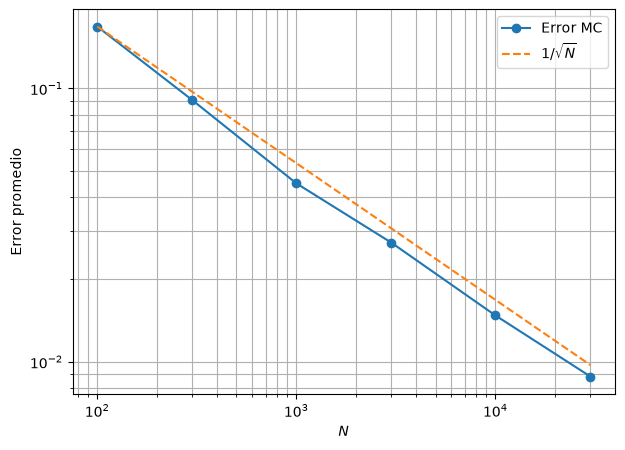

In [19]:
plt.figure(figsize=(7, 5))
plt.loglog(Ns, errores, 'o-', label='Error MC')
plt.loglog(Ns, [errores[0]*np.sqrt(Ns[0]/N) for N in Ns], '--', label=r'$1/\sqrt{N}$')
plt.xlabel('$N$')
plt.ylabel('Error promedio')
plt.grid(True, which='both')
plt.legend()
plt.show()

El error baja como $1/\sqrt{N}$. Como en clase, también hacemos el histograma de las áreas. La desviación esperada es $\sigma_I=(b-a)\sigma_f/\sqrt{N}$, y para $\sqrt{x}$ en $[0,4]$ se tiene $\sigma_f=\sqrt{\langle f^2\rangle-\langle f\rangle^2}=\sqrt{2-16/9}=\sqrt{2}/3$.

Media: 5.333537390086328
Desviación: 0.05863184898612675  teórica: 0.0596284793999944


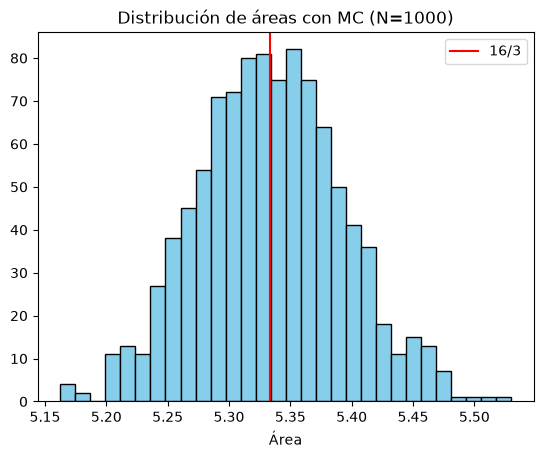

In [20]:
N = 1000
areas = []
for i in range(1000):
    areas.append(monte_carlo_integration(f, a, b, N))

# Desviación teórica
sigma_teorica = (b - a)*(np.sqrt(2)/3)/np.sqrt(N)
print("Media:", np.mean(areas))
print("Desviación:", np.std(areas), " teórica:", sigma_teorica)

plt.hist(areas, bins=30, ec="black", color='skyblue')
plt.axvline(analitico, color='r', label='16/3')
plt.title(f"Distribución de áreas con MC (N={N})")
plt.xlabel("Área")
plt.legend()
plt.show()

### Punto 2

Modificación de la rutina para 2D: se toman puntos aleatorios en el rectángulo y se multiplica por su área $(b-a)(d-c)$.

$\int_0^2\int_0^1 xy^2\,dy\,dx = (\int_0^2 x\,dx)(\int_0^1 y^2\,dy) = 2\cdot\frac{1}{3} = 2/3$

In [21]:
# Rutina de clase modificada para 2D
def monte_carlo_integration_2D(func, a, b, c, d, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = random.uniform(a, b)
        y = random.uniform(c, d)
        integral_sum += func(x, y)
    return (b - a)*(d - c)*(integral_sum / num_samples) # promedio por el área

In [22]:
# Inciso punto 2
f2 = lambda x, y: x*y**2

valor_mc_2 = monte_carlo_integration_2D(f2, 0, 2, 0, 1, 100000)

# dblquad recibe f(y, x)
print("Valor con dblquad:", integrate.dblquad(lambda y, x: f2(x, y), 0, 2, 0, 1)[0])
print("Valor con MC:", valor_mc_2)
print(f"Error relativo: {abs(valor_mc_2 - 2/3)/(2/3)*100:.4f} %")

Valor con dblquad: 0.6666666666666667
Valor con MC: 0.6657622300531377
Error relativo: 0.1357 %


**Conclusión del ejercicio:** Con Monte Carlo las dos integrales se acercan al valor analítico ($16/3$ y $2/3$). El error baja como $1/\sqrt{N}$, que es más lento que `quad`, pero la rutina se puede pasar fácilmente a 2D o más dimensiones.

## Ejercicio 3

Como los átomos no interactúan, la energía es $E=-\mu_0H\sum_i s_i$, y al voltear un espín $s_i\to-s_i$ el cambio de energía es

$$\Delta E = 2\mu_0 H s_i$$

Se usa el mismo criterio de Metropolis de clase, $A=\min(1,P(x')/P(x))$, que con la distribución canónica queda $A=\min(1,e^{-\Delta E/k_BT})$.

**Justificación:** Se crea una red cúbica $L\times L\times L$ con espines aleatorios. En cada barrido se recorren todos los espines y se intenta voltear cada uno con la regla de Metropolis. Primero se hacen unos barridos para llegar al equilibrio y después se promedia la magnetización $M=\frac{1}{N}\sum s_i$. Esto se repite para cada $H$ y cada $T$. Se usan unidades reducidas $\mu_0=k_B=1$, así lo que importa es el cociente $H/T$.

In [23]:
# Parámetros
L = 8          
mu0 = 1.0      
kB = 1.0

def red_inicial(L):
    return np.random.choice([-1, 1], size=(L, L, L))

def barrido_metropolis(spins, H, T):
    L = spins.shape[0]
    for i in range(L):
        for j in range(L):
            for k in range(L):
                s = spins[i, j, k]
                # Cambio de energía al voltear el espín
                dE = 2*mu0*H*s
                # Criterio de Metropolis
                if dE <= 0 or random.random() < math.exp(-dE/(kB*T)):
                    spins[i, j, k] = -s
    return spins

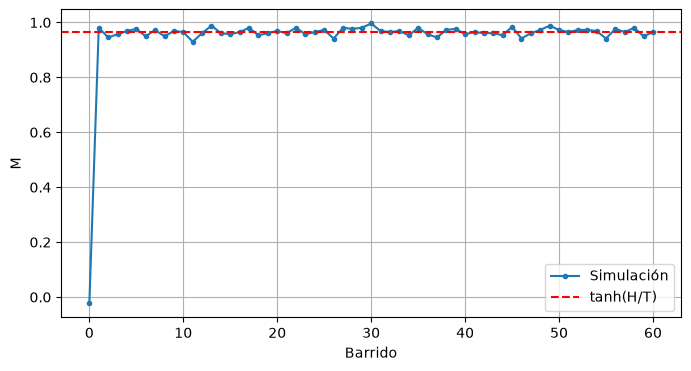

In [24]:
# Revisar cuántos barridos se necesitan para llegar al equilibrio 
spins = red_inicial(L)
M_barridos = [np.mean(spins)]

for n in range(60):
    spins = barrido_metropolis(spins, 10, 5)
    M_barridos.append(np.mean(spins))

plt.figure(figsize=(8, 4))
plt.plot(M_barridos, 'o-', ms=3, label='Simulación')
plt.axhline(np.tanh(10/5), color='r', ls='--', label='tanh(H/T)')
plt.xlabel('Barrido')
plt.ylabel('M')
plt.grid()
plt.legend()
plt.show()

In [25]:

def magnetizacion_media(H, T, L=8, n_equilibrio=20, n_medidas=80):
    spins = red_inicial(L)

    # 1. Barridos para llegar al equilibrio
    for _ in range(n_equilibrio):
        spins = barrido_metropolis(spins, H, T)

    # 2. Barridos para medir
    M = []
    for _ in range(n_medidas):
        spins = barrido_metropolis(spins, H, T)
        M.append(np.mean(spins))
    return np.mean(M)

In [26]:
# Temperaturas en K y campo en G
temperaturas = [5, 10, 15]
campos = np.linspace(-30, 30, 25)

M_T = []
for T in temperaturas:
    M_T.append([magnetizacion_media(H, T, L) for H in campos])

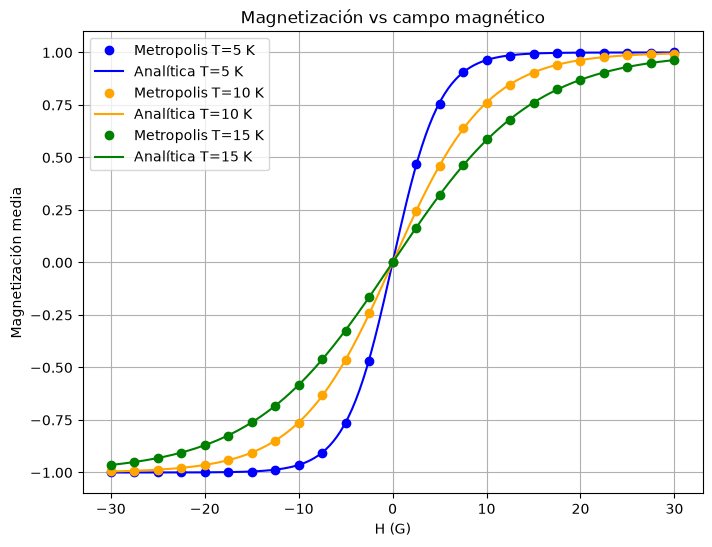

In [27]:
H_fino = np.linspace(-30, 30, 300)
colores = ['b', 'orange', 'g']

# Grafica: simulación y solución analítica
plt.figure(figsize=(8, 6))
for n in range(3):
    T = temperaturas[n]
    plt.plot(campos, M_T[n], 'o', color=colores[n], label=f'Metropolis T={T} K')
    plt.plot(H_fino, np.tanh(mu0*H_fino/(kB*T)), '-', color=colores[n], label=f'Analítica T={T} K')

plt.xlabel('H (G)')
plt.ylabel('Magnetización media')
plt.title('Magnetización vs campo magnético')
plt.grid()
plt.legend()
plt.show()

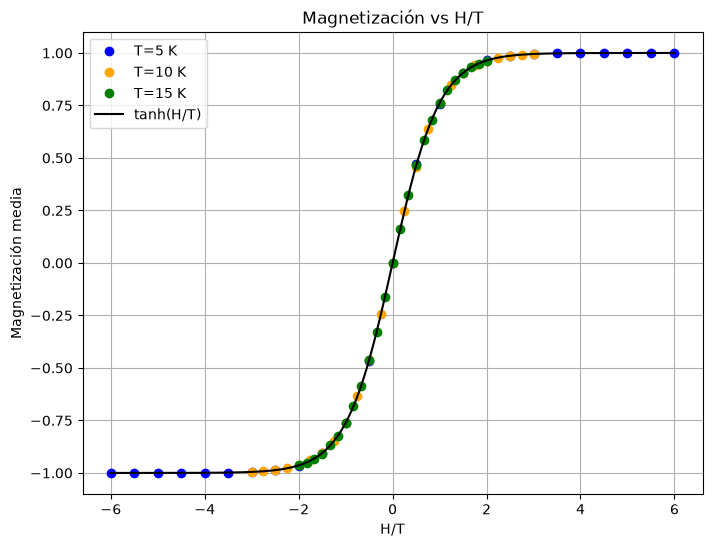

T = 5 K  error máximo: 0.0070
T = 10 K  error máximo: 0.0038
T = 15 K  error máximo: 0.0070


In [28]:
# Magnetización vs H/T
x = np.linspace(-6, 6, 300)

plt.figure(figsize=(8, 6))
for n in range(3):
    T = temperaturas[n]
    plt.plot(campos/T, M_T[n], 'o', color=colores[n], label=f'T={T} K')
plt.plot(x, np.tanh(x), 'k-', label='tanh(H/T)')
plt.xlabel('H/T')
plt.ylabel('Magnetización media')
plt.title('Magnetización vs H/T')
plt.grid()
plt.legend()
plt.show()

for n in range(3):
    T = temperaturas[n]
    print(f"T = {T} K  error máximo: {np.max(np.abs(np.array(M_T[n]) - np.tanh(campos/T))):.4f}")

**Conclusión del ejercicio:** La magnetización obtenida con Metropolis coincide con la solución analítica $\tanh(\mu_0H/k_BT)$ para las tres temperaturas. Con $H=0$ la magnetización es cero porque sin interacción no hay magnetización espontánea. A menor temperatura la curva se satura más rápido. Al graficar contra $H/T$ las tres curvas quedan sobre la misma, entonces la magnetización solo depende de $H/T$.